# Directional Coupler -- 2D FDTD Sweep (gap_um x coupling_length_um)

`06_directional_coupler.ipynb` characterizes the coupler at a single gap,
`gap_um=0.2`. The lattice filters in `circuits/` need coupler stages with very
different cross fractions, including stages close to full transfer, and every
stage's split ratio drifts with wavelength. This notebook maps how the gap changes
both the cross fraction and that wavelength dependence.

It extends the 7-point `coupling_length_um` sweep at `gap_um=0.2`
(`2, 6, 10, 14, 18, 22, 26` µm, `si/data/sparams/coupler/sweep_res40/`) with four more
gaps -- `0.15, 0.25, 0.30, 0.35` µm -- to a 5 x 7 grid (28 new FDTD points + the 7
existing ones). The gap range matches the one `add_drop_ring.py` uses on the same
cross-section (`wg_width_um=0.5`, `core_index=2.7`, `clad_index=1.44`). Every point
runs at `resolution=40` (8 cells across a 200 nm gap); a convergence study showed
`resolution=25` is under-converged for this coupler (`docs/simulation_settings_record.md`).
Gaps below ~0.15 µm are not attempted: at this resolution they are too few cells wide.

Throughout, $K=|S_\mathrm{cross}|^2$ is the **power** cross fraction (the field
coupling coefficient of coupled-mode theory is written $\kappa_c$).

**Scope**: the raw lookup table and what it shows. Feeding the 2D grid into
`coupler_library.py`'s interpolation surrogate (which interpolates over length at one
gap) is not done here.

**Do not use "Run All."** Section 2 runs 28 FDTD simulations on a first run.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pic_toolkit import style
from pic_toolkit.meep_sim import coupler

style.apply_style()
%matplotlib inline

GAPS = [0.15, 0.20, 0.25, 0.30, 0.35]
LENGTHS = [2.0, 6.0, 10.0, 14.0, 18.0, 22.0, 26.0]
WL0_UM = 1.35

# resolution=40 -- a convergence study showed resolution=25 is substantially
# under-converged for this coupler geometry.
OLD_SWEEP_DIR = Path("../data/sparams/coupler/sweep_res40")   # gap=0.20, resolution=40
NEW_SWEEP_DIR = Path("../data/sparams/coupler/sweep_2d_res40")  # this notebook's new points, resolution=40

## 2. The 2D sweep

> **STOP -- this cell runs 28 FDTD simulations on a first run (several minutes each
> at `resolution=40`).** Points whose artifact already exists under `sweep_2d_res40/`
> are skipped. The `gap_um=0.2` column is not simulated here; it is read from
> `si/data/sparams/coupler/sweep_res40/`.

In [2]:
import platform
from datetime import date
import meep as mp

GAPS_NEW = [g for g in GAPS if g != 0.20]  # 0.20 already cached in OLD_SWEEP_DIR
NEW_SWEEP_DIR.mkdir(parents=True, exist_ok=True)

sweep_rows = []
for gap in GAPS_NEW:
    for Lc in LENGTHS:
        stem = NEW_SWEEP_DIR / f"coupler_gap{gap}_couplinglength{Lc}"
        if (stem.parent / (stem.name + ".npz")).exists():
            print(f"gap_um={gap} Lc={Lc}: already exists, skipping re-simulation")
            continue
        params = {**coupler.DEFAULT_PARAMS, "gap_um": gap, "coupling_length_um": Lc}
        result = coupler.simulate_baseline(params)
        validation = coupler.run_all_checks(result)
        print(f"gap_um={gap} Lc={Lc}: validation passed={validation['passed']}")
        metadata = {
            "component": "coupler", "gap_um": gap, "coupling_length_um": Lc,
            "validation": validation, "meep_version": mp.__version__,
            "python_version": platform.python_version(), "creation_date": date.today().isoformat(),
        }
        coupler.save_artifact(stem, result, metadata)
        sweep_rows.append({"gap_um": gap, "coupling_length_um": Lc, "validation_passed": validation["passed"]})

print(f"\n{len(sweep_rows)} new points simulated this run (any already-existing points were skipped above).")

gap_um=0.15 Lc=2.0: already exists, skipping re-simulation
gap_um=0.15 Lc=6.0: already exists, skipping re-simulation
gap_um=0.15 Lc=10.0: already exists, skipping re-simulation
gap_um=0.15 Lc=14.0: already exists, skipping re-simulation
gap_um=0.15 Lc=18.0: already exists, skipping re-simulation
gap_um=0.15 Lc=22.0: already exists, skipping re-simulation
gap_um=0.15 Lc=26.0: already exists, skipping re-simulation
gap_um=0.25 Lc=2.0: already exists, skipping re-simulation
gap_um=0.25 Lc=6.0: already exists, skipping re-simulation
gap_um=0.25 Lc=10.0: already exists, skipping re-simulation
gap_um=0.25 Lc=14.0: already exists, skipping re-simulation
gap_um=0.25 Lc=18.0: already exists, skipping re-simulation
gap_um=0.25 Lc=22.0: already exists, skipping re-simulation
gap_um=0.25 Lc=26.0: already exists, skipping re-simulation
gap_um=0.3 Lc=2.0: already exists, skipping re-simulation
gap_um=0.3 Lc=6.0: already exists, skipping re-simulation
gap_um=0.3 Lc=10.0: already exists, skipping re-

## 3. Load the full 5x7 grid and validate

In [3]:
def load_point(gap, Lc):
    if gap == 0.20:
        stem = OLD_SWEEP_DIR / f"coupler_couplinglength{Lc}"
    else:
        stem = NEW_SWEEP_DIR / f"coupler_gap{gap}_couplinglength{Lc}"
    npz_path = stem.parent / (stem.name + ".npz")
    json_path = stem.parent / (stem.name + ".json")
    data = np.load(npz_path)
    import json
    meta = json.loads(json_path.read_text())
    return data, meta


grid = {}
validation_rows = []
for gap in GAPS:
    for Lc in LENGTHS:
        data, meta = load_point(gap, Lc)
        grid[(gap, Lc)] = data
        validation_rows.append({"gap_um": gap, "coupling_length_um": Lc, "passed": meta["validation"]["passed"]})

validation_df = pd.DataFrame(validation_rows)
print(f"loaded {len(grid)} grid points (expected 35)")
print(f"validation: {validation_df['passed'].sum()}/{len(validation_df)} passed")
validation_df[~validation_df["passed"]]

loaded 35 grid points (expected 35)


validation: 35/35 passed


,gap_um,coupling_length_um,passed


## 4. Cross fraction $K(\mathrm{gap}, L_c)$ at $\lambda_0$

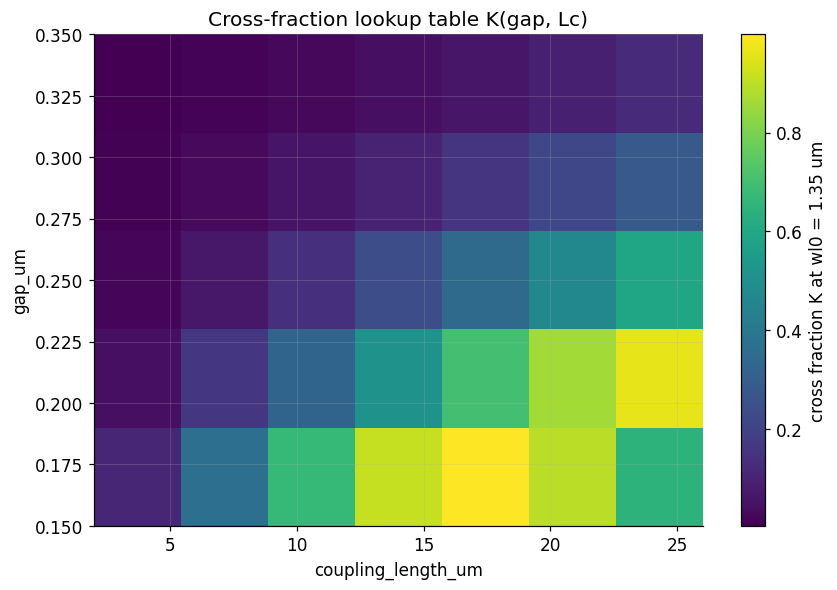

,Lc=2.0,Lc=6.0,Lc=10.0,Lc=14.0,Lc=18.0,Lc=22.0,Lc=26.0
gap=0.15,0.1103,0.3662,0.6712,0.9118,0.9989,0.8977,0.6472
gap=0.2,0.0461,0.1598,0.3238,0.5138,0.7022,0.8591,0.9633
gap=0.25,0.0194,0.0676,0.1416,0.2374,0.3487,0.4694,0.5922
gap=0.3,0.0082,0.0283,0.0599,0.1022,0.1540,0.2145,0.2817
gap=0.35,0.0035,0.0118,0.0250,0.0428,0.0651,0.0916,0.1222


In [4]:
K_at_wl0 = np.zeros((len(GAPS), len(LENGTHS)))
for i, gap in enumerate(GAPS):
    for j, Lc in enumerate(LENGTHS):
        data = grid[(gap, Lc)]
        wl = data["wavelengths_um"]
        order = np.argsort(wl)
        idx_wl0 = int(np.argmin(np.abs(wl[order] - WL0_UM)))
        K_at_wl0[i, j] = np.abs(data["S_cross"][order][idx_wl0]) ** 2

fig, ax = plt.subplots(figsize=(8, 5.5))
im = ax.imshow(K_at_wl0, aspect="auto", origin="lower", cmap=style.CMAP_DENSITY,
                extent=[LENGTHS[0], LENGTHS[-1], GAPS[0], GAPS[-1]])
fig.colorbar(im, ax=ax, label="cross fraction K at wl0 = 1.35 um")
ax.set_xlabel("coupling_length_um"); ax.set_ylabel("gap_um")
ax.set_title("Cross-fraction lookup table K(gap, Lc)")
fig.tight_layout(); plt.show()

K_df = pd.DataFrame(K_at_wl0, index=[f"gap={g}" for g in GAPS], columns=[f"Lc={L}" for L in LENGTHS])
K_df.round(4)

## 5. Through and cross power vs. wavelength, per gap

One row per gap, so the change of the whole wavelength dependence with gap is visible,
not just the value at one design wavelength.

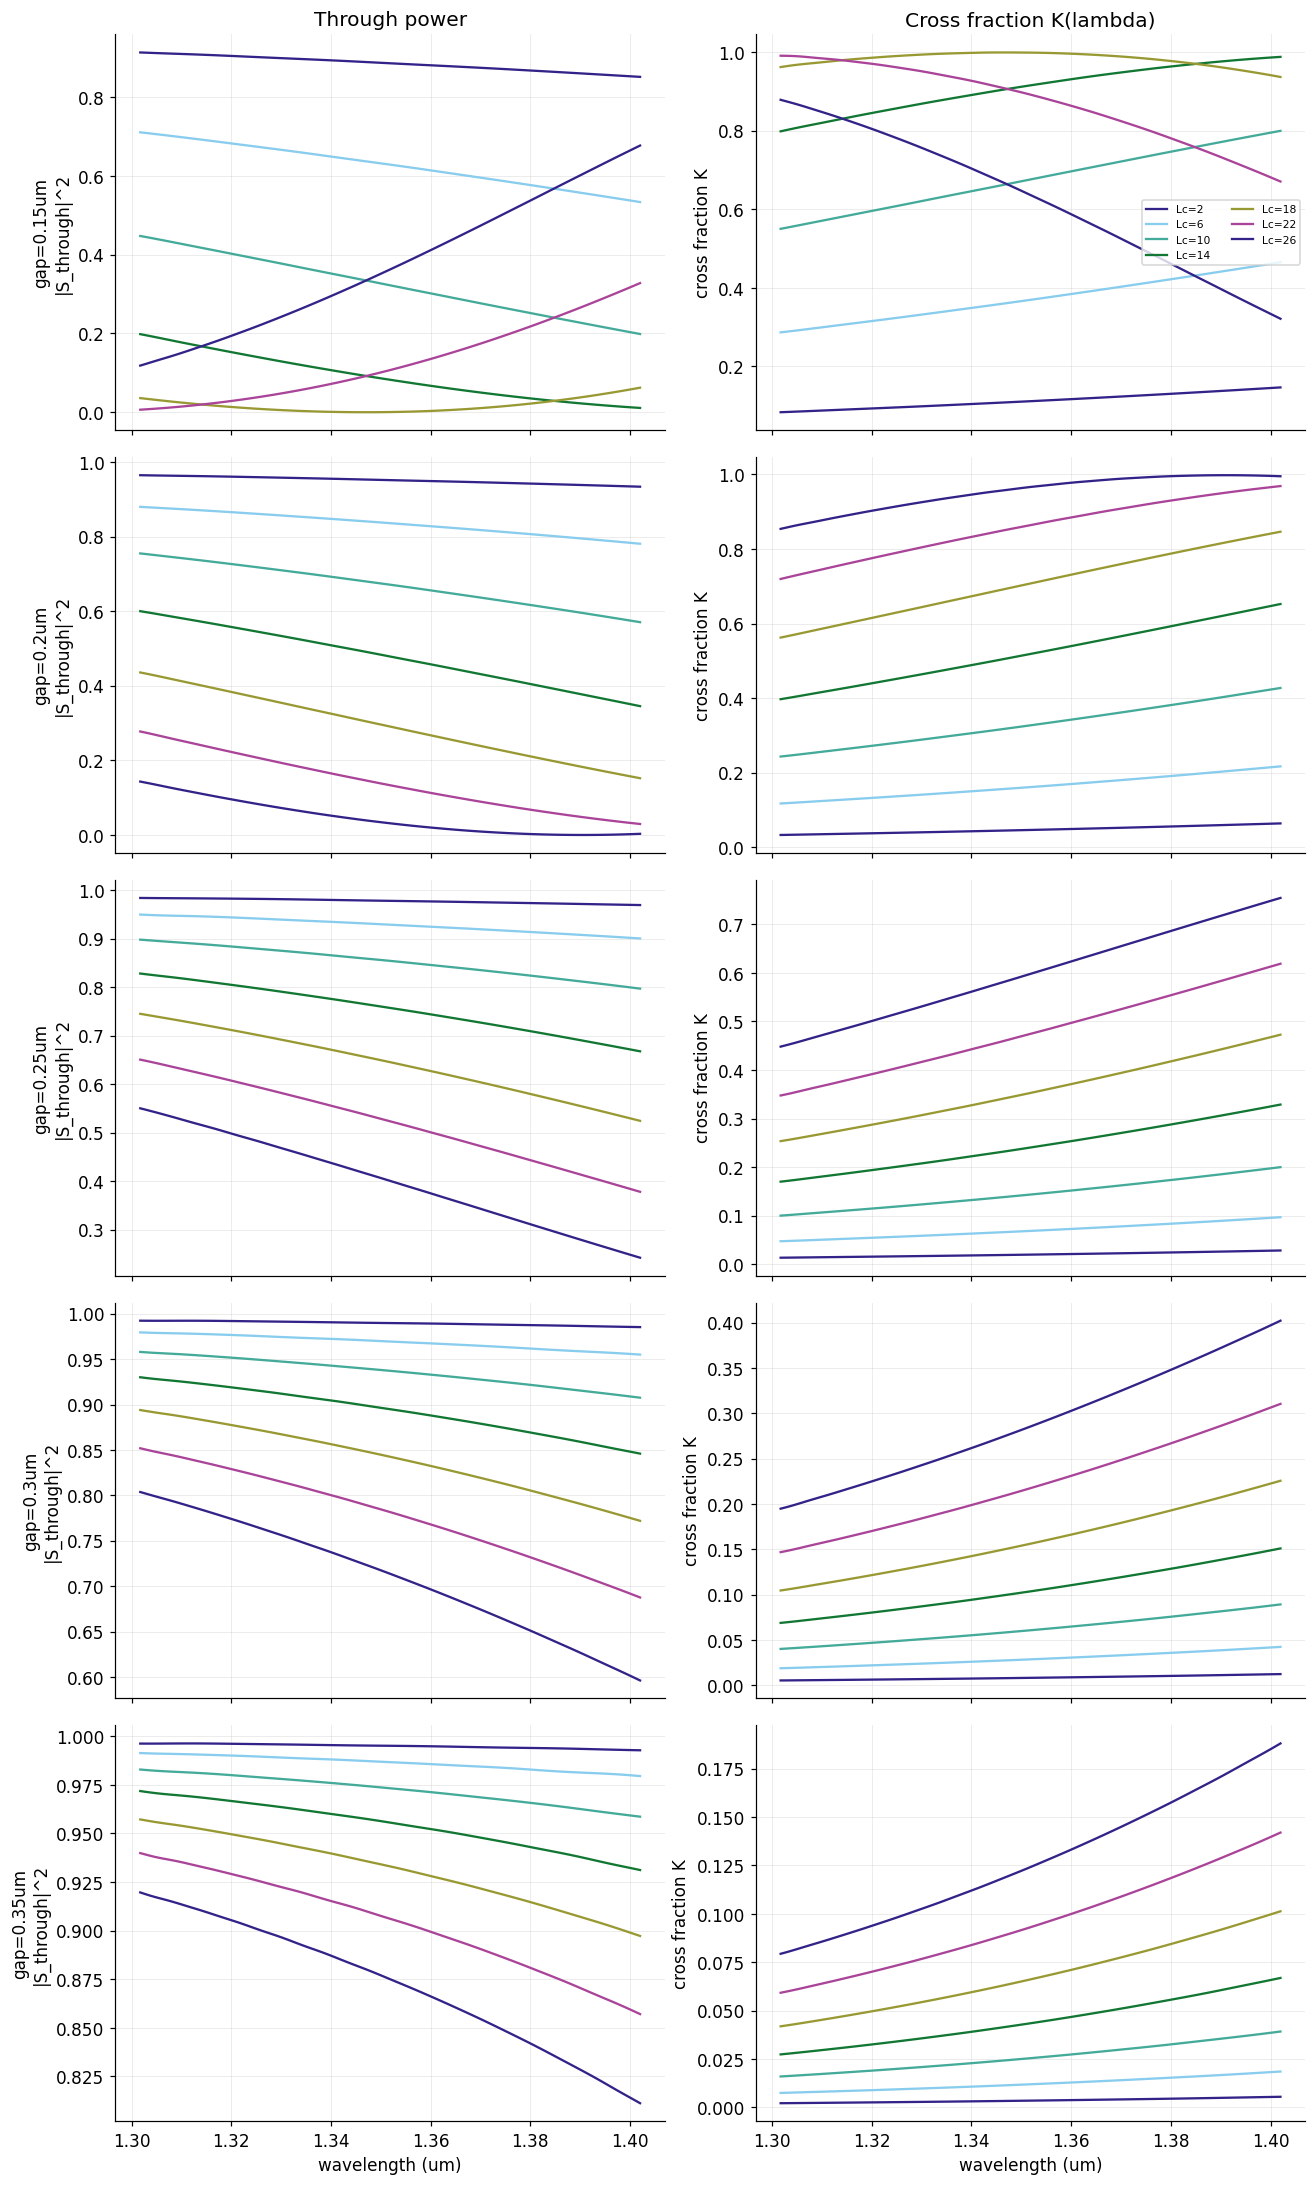

In [5]:
fig, axes = plt.subplots(len(GAPS), 2, figsize=(12, 4 * len(GAPS)), sharex=True)
for i, gap in enumerate(GAPS):
    ax_mag, ax_K = axes[i]
    for Lc in LENGTHS:
        data = grid[(gap, Lc)]
        wl = data["wavelengths_um"]
        order = np.argsort(wl)
        wl_sorted = wl[order]
        through = np.abs(data["S_through"][order]) ** 2
        K_wl = np.abs(data["S_cross"][order]) ** 2
        ax_mag.plot(wl_sorted, through, label=f"Lc={Lc:.0f}")
        ax_K.plot(wl_sorted, K_wl, label=f"Lc={Lc:.0f}")
    ax_mag.set_ylabel(f"gap={gap}um\n|S_through|^2")
    ax_K.set_ylabel("cross fraction K")
    if i == 0:
        ax_mag.set_title("Through power"); ax_K.set_title("Cross fraction K(lambda)")
        ax_K.legend(fontsize=7, ncol=2)
axes[-1, 0].set_xlabel("wavelength (um)"); axes[-1, 1].set_xlabel("wavelength (um)")
fig.tight_layout(); plt.show()

## 6. Split-ratio dispersion across gaps

**What carries the dispersion.** For a symmetric, lossless coupler the cross and
through fields are in quadrature, $\arg(S_\mathrm{cross}/S_\mathrm{through})=\pm\pi/2$,
at every wavelength. The relative phase therefore carries no information about
dispersion; it only jumps by $\pi$ where the through power passes through zero
(full transfer inside the band). The first cell below checks this. All the
wavelength dependence sits in the split ratio, which coupled-mode theory writes as

$$K(\lambda)=\sin^2\phi(\lambda),\qquad \phi=\kappa_c(\lambda)\,(L_c+L_0),$$

where $L_0$ is the extra coupling of the two S-bends. With $\phi$ fixed by the target
$K$, the split-ratio slope is

$$\frac{dK}{d\lambda}=\sin 2\phi\;\phi\;\frac{d\ln\kappa_c}{d\lambda}.$$

The last factor is a property of the gap alone: the evanescent overlap between the two
guides decays faster with distance at shorter wavelength, and the relative change with wavelength is larger the wider the gap.
The second cell measures $dK/d\lambda$ at $\lambda_0$ for every point and the
gap-only factor $(1/\phi)\,d\phi/d\lambda$ from the points before full transfer.

In [6]:
# (1) Relative phase arg(S_cross/S_through): its largest distance from +-90 deg over the band,
# and the smallest through power in the band (a zero there makes the phase jump by pi).
def sorted_point(data):
    order = np.argsort(data["wavelengths_um"])
    return data["wavelengths_um"][order], data["S_through"][order], data["S_cross"][order]

quad_rows = []
for gap in GAPS:
    for Lc in LENGTHS:
        wl, s_t, s_c = sorted_point(grid[(gap, Lc)])
        rel = np.angle(s_c / s_t)
        quad_rows.append({"gap_um": gap, "coupling_length_um": Lc,
                          "max_dev_from_quadrature_deg": float(np.degrees(np.max(np.abs(np.abs(rel) - np.pi / 2)))),
                          "min_through_power": float(np.min(np.abs(s_t) ** 2))})
quad_df = pd.DataFrame(quad_rows)
print("largest distance of arg(S_cross/S_through) from +-90 deg over the band (deg):")
print(quad_df.pivot(index="gap_um", columns="coupling_length_um", values="max_dev_from_quadrature_deg").round(1))
print("\npoints whose through power reaches ~0 inside the band (full transfer):")
print(quad_df[quad_df["min_through_power"] < 1e-3][["gap_um", "coupling_length_um", "min_through_power"]].to_string(index=False))

largest distance of arg(S_cross/S_through) from +-90 deg over the band (deg):
coupling_length_um  2.0   6.0   10.0  14.0  18.0  22.0  26.0
gap_um                                                      
0.15                 0.1   0.0   0.1   0.2  19.1   0.1   0.1
0.20                 0.1   0.1   0.1   0.1   0.1   0.1  28.0
0.25                 0.2   0.2   0.1   0.1   0.1   0.1   0.1
0.30                 0.2   0.2   0.2   0.1   0.1   0.1   0.1
0.35                 0.2   0.1   0.2   0.2   0.1   0.1   0.1

points whose through power reaches ~0 inside the band (full transfer):
 gap_um  coupling_length_um  min_through_power
   0.15                18.0       8.041463e-08
   0.20                26.0       2.474396e-06


dK/dlambda at wl0, per 100 nm:
coupling_length_um   2.0    6.0    10.0   14.0   18.0   22.0   26.0
gap_um                                                             
0.15                0.062  0.177  0.253  0.199 -0.011 -0.316 -0.581
0.20                0.030  0.098  0.182  0.256  0.290  0.262  0.160
0.25                0.014  0.048  0.098  0.157  0.219  0.273  0.313
0.30                0.007  0.023  0.048  0.081  0.119  0.161  0.205
0.35                0.003  0.011  0.023  0.038  0.058  0.080  0.106

gap-only factor (1/phi) dphi/dlambda (1/um), points before full transfer:
         mean    std  count
gap_um                     
0.15    2.836  0.060      4
0.20    3.231  0.055      6
0.25    3.650  0.042      7
0.30    4.096  0.040      7
0.35    4.543  0.040      7


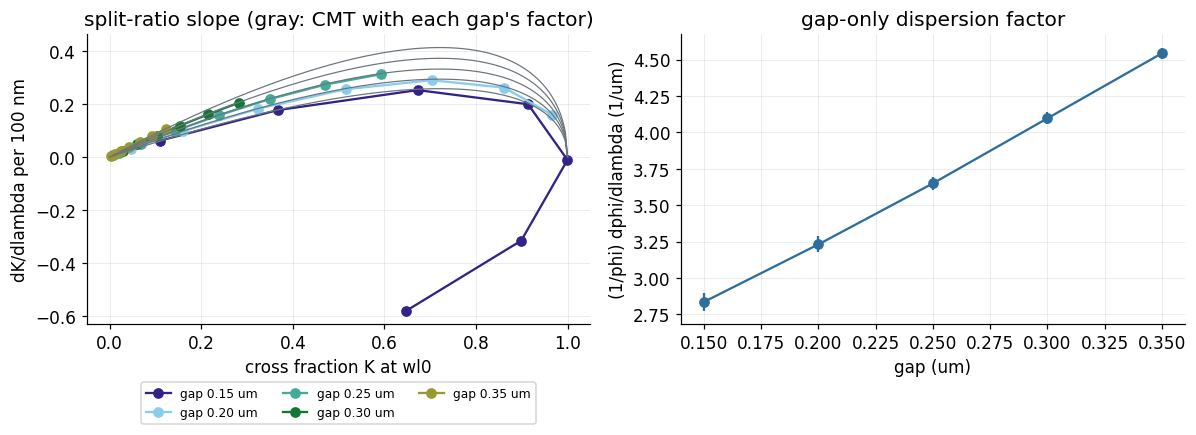

In [7]:
# (2) Split-ratio slope dK/dlambda at wl0 (linear fit over 1.33-1.37 um, quoted per 100 nm), and
# the gap-only factor (1/phi) dphi/dlambda with phi = arcsin(sqrt(K)), taken from the points
# before full transfer (K rising with Lc and no through-power zero in the band).
FIT_WINDOW = (1.33, 1.37)
disp_rows = []
for gap in GAPS:
    K0_along_L = []
    for Lc in LENGTHS:
        wl, s_t, s_c = sorted_point(grid[(gap, Lc)])
        K = np.abs(s_c) ** 2 / (np.abs(s_c) ** 2 + np.abs(s_t) ** 2)   # normalized by the output power
        sel = (wl > FIT_WINDOW[0]) & (wl < FIT_WINDOW[1])
        i0 = int(np.argmin(np.abs(wl - WL0_UM)))
        phi = np.arcsin(np.sqrt(K))
        disp_rows.append({"gap_um": gap, "coupling_length_um": Lc, "K_wl0": float(K[i0]),
                          "dK_per_100nm": float(np.polyfit(wl[sel], K[sel], 1)[0] * 0.1),
                          "rel_phase_disp_per_um": float(np.polyfit(wl[sel], phi[sel], 1)[0] / phi[i0]),
                          "min_through_power": float(np.min(np.abs(s_t) ** 2))})
disp_df = pd.DataFrame(disp_rows)
# before full transfer: K at wl0 still rising with Lc, and no through-power zero in the band
disp_df["before_full_transfer"] = False
for gap in GAPS:
    sub = disp_df[disp_df["gap_um"] == gap].sort_values("coupling_length_um")
    rising = np.r_[True, np.diff(sub["K_wl0"].values) > 0]
    first_drop = np.argmin(rising) if not rising.all() else len(rising)
    ok = (np.arange(len(sub)) < first_drop) & (sub["min_through_power"].values > 1e-2)
    disp_df.loc[sub.index[ok], "before_full_transfer"] = True

print("dK/dlambda at wl0, per 100 nm:")
print(disp_df.pivot(index="gap_um", columns="coupling_length_um", values="dK_per_100nm").round(3))
gap_factor = disp_df[disp_df["before_full_transfer"]].groupby("gap_um")["rel_phase_disp_per_um"].agg(["mean", "std", "count"])
print("\ngap-only factor (1/phi) dphi/dlambda (1/um), points before full transfer:")
print(gap_factor.round(3))

fig, (ax_k, ax_g) = plt.subplots(1, 2, figsize=(11, 4.2))
for c, gap in zip(style.COLOR_CYCLE, GAPS):
    sub = disp_df[disp_df["gap_um"] == gap]
    ax_k.plot(sub["K_wl0"], sub["dK_per_100nm"], "o-", color=c, label=f"gap {gap:.2f} um")
k = np.linspace(0, 1, 200)
for gap in GAPS:   # CMT curve with each gap's measured factor: dK/dlambda = sin(2 phi) phi g
    phi = np.arcsin(np.sqrt(k))
    ax_k.plot(k, np.sin(2 * phi) * phi * gap_factor.loc[gap, "mean"] * 0.1, color=style.COLOR_REFERENCE, lw=0.8)
ax_k.set_xlabel("cross fraction K at wl0"); ax_k.set_ylabel("dK/dlambda per 100 nm")
ax_k.set_title("split-ratio slope (gray: CMT with each gap's factor)")
ax_k.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
ax_g.errorbar(gap_factor.index, gap_factor["mean"], yerr=gap_factor["std"], fmt="o-", color=style.COLOR_STEEL)
ax_g.set_xlabel("gap (um)"); ax_g.set_ylabel("(1/phi) dphi/dlambda (1/um)")
ax_g.set_title("gap-only dispersion factor")
fig.tight_layout(); plt.show()

## 7. Continuity check against the gap = 0.20 µm column

The `gap=0.20` row comes from `si/data/sparams/coupler/sweep_res40/`, simulated
separately from the other four gaps. At every fixed length the cross fraction should
vary smoothly across the gap axis, with no step at 0.20 µm.

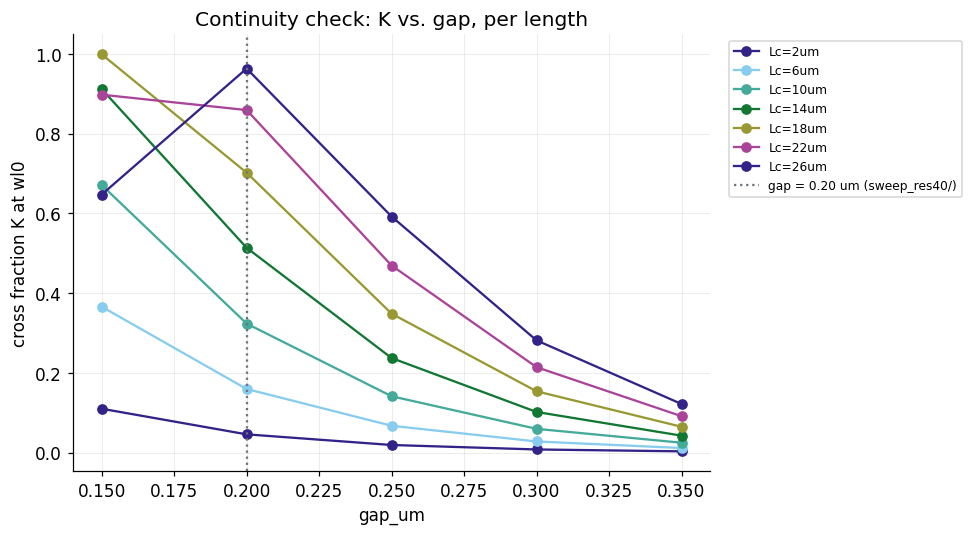

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
for Lc in LENGTHS:
    K_vs_gap = [K_at_wl0[GAPS.index(g), LENGTHS.index(Lc)] for g in GAPS]
    ax.plot(GAPS, K_vs_gap, marker="o", label=f"Lc={Lc:.0f}um")
ax.axvline(0.20, color=style.COLOR_REFERENCE, ls=":", label="gap = 0.20 um (sweep_res40/)")
ax.set_xlabel("gap_um"); ax.set_ylabel("cross fraction K at wl0")
ax.set_title("Continuity check: K vs. gap, per length")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1.0)); fig.tight_layout(); plt.show()

## 8. Conclusions

**All 35 grid points pass validation** (energy conservation, reciprocity, passivity)
at `resolution=40`.

**The cross-fraction table (Section 4) behaves as coupled-mode theory predicts.** At
`gap=0.15` µm, $K$ reaches full transfer near $L_c=18$ µm ($K=0.999$) and falls again
(0.898 at 22 µm, 0.647 at 26 µm). At `gap=0.20` µm it is still rising at 26 µm
($K=0.963$); full transfer falls just inside the band there, at the long-wavelength end.
Section 7 shows $K$ varying smoothly across all five gaps at every length, with no step
at the separately simulated 0.20 µm column.

**The relative phase is fixed by symmetry.** $\arg(S_\mathrm{cross}/S_\mathrm{through})$
stays within 0.2° of ±90° at 33 of the 35 points. The two exceptions,
(0.15 µm, 18 µm) and (0.20 µm, 26 µm), are exactly the points where the through power
passes through zero inside the band, and the phase jumps by π there. The relative phase
therefore cannot rank couplers by dispersion.

**The split-ratio dispersion follows one law per gap.** The factor
$(1/\phi)\,d\phi/d\lambda$ is constant along the length axis (scatter about 2 %) and grows
linearly with the gap: 2.84, 3.23, 3.65, 4.10 and 4.54 µm⁻¹ from 0.15 to 0.35 µm. The
slope of every point before full transfer then follows
$dK/d\lambda=\sin 2\phi\;\phi\;(1/\phi)\,d\phi/d\lambda$ (gray curves). Two design rules
follow:

- **At a given target ratio, a narrower gap is less dispersive.** The split-ratio slope
  scales with the gap factor: going from 0.20 µm to 0.15 µm lowers it by 12 %, and going
  to 0.35 µm raises it by 41 %.
- **The slope peaks near $K\approx0.7$ and falls to zero at full transfer**, where
  $\sin 2\phi\to0$. Past full transfer ($\phi>\pi/2$, the falling branch at
  `gap=0.15` µm) the slope changes sign and grows again with $\phi$. A high-ratio stage
  (e.g. $K\approx0.93$) is therefore best realized on the rising branch, as close to full
  transfer as the target allows, not past it.

The gain from changing the gap is modest (tens of percent, not orders of magnitude).
Feeding this 2D grid into `coupler_library.py`'s interpolation surrogate, so that a
lattice-filter design can choose gap and length together, is not done here.
